# Analisi modale della Sala "Danger" — verifica della teoria di Schroeder

**Dati**: 5 posizioni microfoniche (`Danger_Pos{1..5}.mdat`, Room EQ Wizard), 3 sweep ESS 20–22 000 Hz per posizione, $f_s = 48$ kHz, sorgente Yamaha HS5, mic ECM8000 calibrato.

**Stanza**: $5.70 \times 4.80 \times 2.48$ m, $V = 67.85$ m³, $S = 106.8$ m² (da `session_260609.md`).

**Obiettivo**: estrarre la risposta all'impulso (IR) per ogni posizione (media coerente dei 3 sweep) e verificare la teoria di Schroeder:

1. sotto la frequenza di Schroeder $f_S$ i modi sono risolti individualmente e corrispondono ai modi teorici della stanza rettangolare;
2. sopra $f_S$ i modi si sovrappongono (overlap modale $M \geq 3$), la risposta diventa statistica e la spaziatura media dei massimi della FR vale $\langle \Delta f_{max} \rangle \simeq 4/T$.

## 1. Parsing dei file `.mdat`

**Formato**: i `.mdat` di REW sono *serializzazione Java* (header `REW Measurement Data File V2`). Il parser generico `javaobj-py3` **fallisce** (`Invalid reference handle`: blocchi `writeObject` custom) → parser dedicato che:

- estrae i **campi primitivi** della classe `roomeqwizard.MeasData` (sample rate, range sweep, `numSweeps`, dimensioni stanza impostate in REW, ...) leggendo il class descriptor e i valori che lo seguono nello stream;
- estrae gli **array `float[]`** tramite scan dei token `TC_ARRAY` (`ur [F` per il descrittore completo, `uq + handle` per i riferimenti successivi).

**Identificazione dell'IR** (reverse engineering): ogni file contiene 3 misure (3 sweep); per ciascuna l'unico array da **131072 campioni** (2.73 s @ 48 kHz) ha la struttura di una IR (picco netto + coda in decadimento) con il picco **esattamente al campione 48000** (1.000 s): REW allinea internamente le IR sul picco. Gli altri array sono risposta in frequenza già calcolata da REW (modulo/fase su bin lineari $\Delta f = 48000/131072 = 0.366$ Hz fino a 22 kHz, `dataLength = 60021`) e curve di calibrazione (identiche fra le 3 misure dello stesso file).

In [2]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent / 'src'))

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks, butter, sosfiltfilt

from rew_io import ROOM_DIR, FIG_DIR, read_mdat

# --- costanti stanza (dagli appunti di sessione, NON dai .mdat: v. anomalie) ---
LX, LY, LZ = 5.70, 4.80, 2.48           # m
V  = LX * LY * LZ                        # 67.85 m^3
S  = 2 * (LX*LY + LX*LZ + LY*LZ)         # 106.8 m^2
LT = 4 * (LX + LY + LZ)                  # somma spigoli, 51.9 m
c  = 343.0                               # m/s (~20 degC)

POSITIONS = [1, 2, 3, 4, 5]
print(f'V = {V:.2f} m3, S = {S:.1f} m2, dati in: {ROOM_DIR}')


V = 67.85 m3, S = 106.8 m2, dati in: /Users/matteob/Code/acoustics/data/room


Il parser `.mdat` vive in [`src/rew_io.py`](../src/rew_io.py) (`parse_measdata_fields`, `extract_irs`, `read_mdat`), condiviso con il notebook di calibrazione invece di essere duplicato qui.


In [3]:
anomalie = []
raw = {}
print(f'{"pos":>3} {"fs":>6} {"sweep [Hz]":>13} {"numSweeps":>9} {"n_IR":>4} '
      f'{"argmax IR":>21} {"corr min":>8} {"lag max":>7} {"SNR dB":>6}')
for pos in POSITIONS:
    m    = read_mdat(ROOM_DIR / f'Danger_Pos{pos}.mdat')
    flds, irs, fs = m.fields, m.irs, m.fs
    if len(irs) != 3:
        anomalie.append(f'Pos{pos}: attese 3 IR, trovate {len(irs)}')
    # coerenza fra i 3 sweep: correlazione e ritardo relativo (cross-correlazione)
    corrs, lags = [], []
    for i in range(len(irs)):
        for j in range(i+1, len(irs)):
            corrs.append(np.corrcoef(irs[i], irs[j])[0, 1])
            a = irs[i][46000:60000]; b = irs[j][46000:60000]
            xc = np.correlate(a - a.mean(), b - b.mean(), 'full')
            lags.append(int(xc.argmax() - (len(a) - 1)))
    if max(abs(l) for l in lags) > 0:
        anomalie.append(f'Pos{pos}: sweep disallineati, lag={lags} campioni')
    if min(corrs) < 0.99:
        anomalie.append(f'Pos{pos}: ripetibilità leggermente ridotta fra sweep, '
                        f'corr min={min(corrs):.3f} (comunque > 0.98)')
    h_mean = np.mean(irs, axis=0)
    snr = 20*np.log10(np.abs(h_mean).max() / np.std(h_mean[:40000]))
    raw[pos] = dict(irs=irs, fs=fs, fields=flds, snr=snr)
    print(f'{pos:>3} {fs:>6} {flds["startFreq"]:>5.1f}-{flds["endFreq"]:<7.0f} '
          f'{flds["numSweeps"]:>9} {len(irs):>4} '
          f'{str([int(np.abs(x).argmax()) for x in irs]):>21} '
          f'{min(corrs):>8.4f} {max(abs(l) for l in lags):>7} {snr:>6.1f}')

FS = raw[1]['fs']
assert all(raw[p]['fs'] == FS for p in POSITIONS)
# dimensioni stanza salvate in REW vs reali
rew_dims = (raw[1]['fields']['roomLength'], raw[1]['fields']['roomWidth'],
            raw[1]['fields']['roomHeight'])
if not np.allclose(rew_dims, (LX, LY, LZ), atol=0.05):
    anomalie.append(f'Dimensioni stanza nei .mdat = {rew_dims} m (default REW non '
                    f'impostato): uso quelle reali {LX}x{LY}x{LZ} m dagli appunti')
anomalie.append('Misure salvate "with no timing reference": l\'allineamento assoluto non '
                'è garantito, ma le IR risultano già allineate da REW (picco al campione '
                '48000, lag inter-sweep = 0) -> media coerente valida')
print('\nAnomalie finora:')
for a in anomalie:
    print(' -', a)

pos     fs    sweep [Hz] numSweeps n_IR             argmax IR corr min lag max SNR dB
  1 48000.0  20.1-22000           1    3 [48000, 48000, 48000]   0.9988       0   82.1
  2 48000.0  20.1-22000           1    3 [48000, 48000, 48000]   0.9909       0   78.7
  3 48000.0  20.1-22000           1    3 [48000, 48000, 48000]   0.9926       0   79.2
  4 48000.0  20.1-22000           1    3 [48000, 48000, 48000]   0.9904       0   80.1
  5 48000.0  20.1-22000           1    3 [48000, 48000, 48000]   0.9882       0   68.2

Anomalie finora:
 - Pos5: ripetibilità leggermente ridotta fra sweep, corr min=0.988 (comunque > 0.98)
 - Dimensioni stanza nei .mdat = (5.0, 4.0, 2.4) m (default REW non impostato): uso quelle reali 5.7x4.8x2.48 m dagli appunti
 - Misure salvate "with no timing reference": l'allineamento assoluto non è garantito, ma le IR risultano già allineate da REW (picco al campione 48000, lag inter-sweep = 0) -> media coerente valida


## 2. Media coerente dei 3 sweep

**Principio**: il segnale deterministico (la IR) si somma *in ampiezza*, il rumore incoerente *in potenza* → la media di $N$ sweep guadagna $10\log_{10} N \approx 4.8$ dB di SNR. La media è valida **solo se le IR sono allineate**: verificato sopra (lag di cross-correlazione = 0 campioni, picco sempre al campione 48000). La correlazione fra sweep ripetuti (> 0.99) misura anche la *ripetibilità*: stanza e catena di misura stabili durante la sessione.

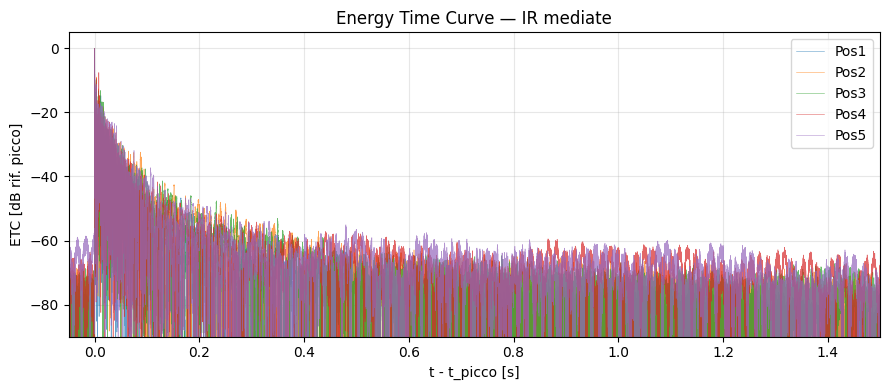

In [4]:
IR  = {pos: np.mean(raw[pos]['irs'], axis=0) for pos in POSITIONS}
IPK = {pos: int(np.abs(IR[pos]).argmax()) for pos in POSITIONS}

fig, ax = plt.subplots(figsize=(9, 4))
for pos in POSITIONS:
    h = IR[pos]
    t = (np.arange(len(h)) - IPK[pos]) / FS
    etc = 20*np.log10(np.abs(h) / np.abs(h).max() + 1e-12)
    ax.plot(t, etc, lw=0.4, alpha=0.7, label=f'Pos{pos}')
ax.set(xlim=(-0.05, 1.5), ylim=(-90, 5), xlabel='t - t_picco [s]',
       ylabel='ETC [dB rif. picco]', title='Energy Time Curve — IR mediate')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 3. Risposta in frequenza

FFT dell'IR completa (131072 campioni → risoluzione $\Delta f = 0.366$ Hz, sufficiente a risolvere modi con larghezza $\Delta f_{3dB} = 2.2/T \approx 2$ Hz a bassa frequenza). Per l'analisi statistica ad alta frequenza (§7) l'IR verrà invece **finestrata per banda** (lunghezza $\sim 3T$): la coda, lì dominata dal rumore, introdurrebbe massimi spuri nel conteggio.

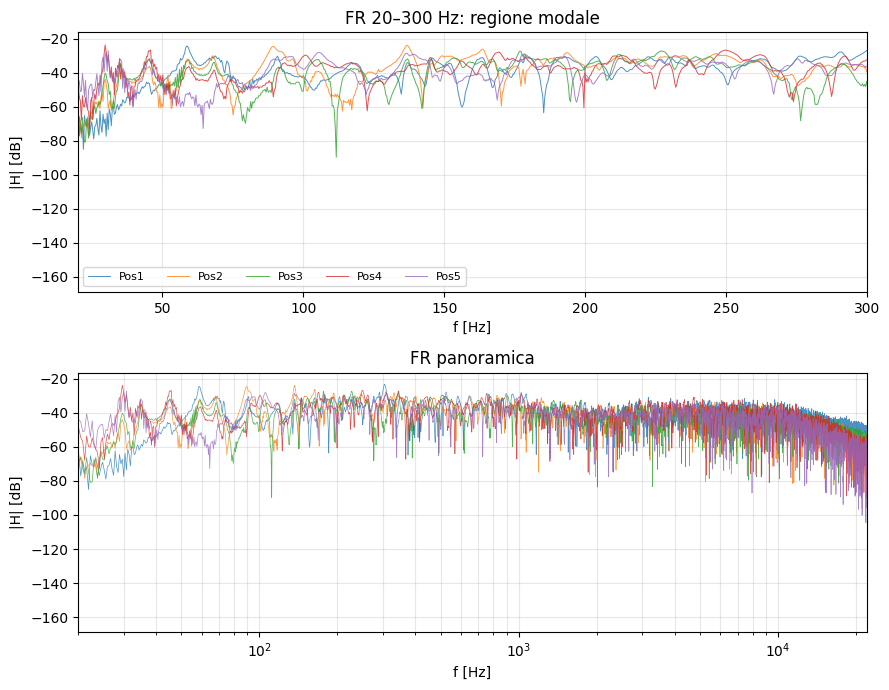

In [5]:
NFFT = 131072
FREQ = np.fft.rfftfreq(NFFT, 1/FS)
MAG  = {pos: 20*np.log10(np.abs(np.fft.rfft(IR[pos], NFFT)) + 1e-30) for pos in POSITIONS}

fig, axs = plt.subplots(2, 1, figsize=(9, 7))
for pos in POSITIONS:
    axs[0].plot(FREQ, MAG[pos], lw=0.7, alpha=0.8, label=f'Pos{pos}')
    axs[1].semilogx(FREQ, MAG[pos], lw=0.5, alpha=0.8)
axs[0].set(xlim=(20, 300), xlabel='f [Hz]', ylabel='|H| [dB]',
           title='FR 20–300 Hz: regione modale')
axs[0].legend(ncol=5, fontsize=8); axs[0].grid(alpha=0.3)
axs[1].set(xlim=(20, 22000), xlabel='f [Hz]', ylabel='|H| [dB]',
           title='FR panoramica')
axs[1].grid(alpha=0.3, which='both')
plt.tight_layout(); plt.show()

## 4. Tempo di riverberazione $T_{20}$ per bande d'ottava

**Principio (integrazione all'indietro di Schroeder)**: la media d'insieme del decadimento quadratico equivale all'integrale dell'energia residua dell'IR, $\langle s^2(t)\rangle \propto \int_t^{\infty} h^2(\tau)\, d\tau$: una singola IR fornisce la curva di decadimento liscia. $T_{20}$: fit lineare del tratto −5 → −25 dB, estrapolato a −60 dB.

**Attenzione al rumore**: integrare anche la coda di rumore appiattisce artificialmente la curva di Schroeder e gonfia $T$. Prima verifica *senza* troncamento: a 63 Hz risultavano $T_{20}$ = 5–9 s, non fisici per 68 m³ (**anomalia**). Rimedio (Lundeby semplificato): stima del floor di rumore dagli ultimi 0.3 s della banda, troncamento dell'integrale dove l'inviluppo scende sotto rumore +10 dB e sottrazione dell'energia del rumore.

 fc [Hz]    Pos1    Pos2    Pos3    Pos4    Pos5   media
      63    1.41    0.89    0.82    0.70    0.92    0.95
     125    1.03    0.96    0.99    0.92    1.03    0.99
     250    0.63    0.67    0.68    0.58    0.75    0.66
     500    0.35    0.31    0.39    0.37    0.32    0.35
    1000    0.20    0.19    0.20    0.18    0.16    0.19
    2000    0.19    0.18    0.18    0.19    0.18    0.18
    4000    0.14    0.15    0.15    0.15    0.15    0.15


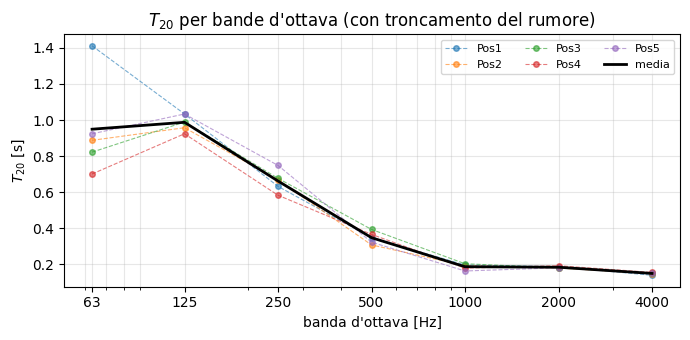

In [6]:
BANDS = [63, 125, 250, 500, 1000, 2000, 4000]

def t20_band(h, fc, fs, trunc=True):
    sos = butter(3, [fc/np.sqrt(2), fc*np.sqrt(2)], 'bandpass', fs=fs, output='sos')
    x = sosfiltfilt(sos, h)
    x = x[int(np.abs(x).argmax()):]
    e = x**2
    if trunc:
        nfl = e[-int(0.3*fs):].mean()                      # floor di rumore (coda)
        k = int(0.05*fs)
        env = np.convolve(e, np.ones(k)/k, 'same')         # inviluppo (50 ms)
        above = np.where(env > 10*nfl)[0]                  # soglia rumore +10 dB
        e = np.clip(e[:above[-1]] - nfl, 0, None) if len(above) else e
    sch = 10*np.log10(np.cumsum(e[::-1])[::-1] / e.sum() + 1e-30)
    t = np.arange(len(e)) / fs
    m = (sch <= -5) & (sch >= -25)
    if m.sum() < 10:
        return np.nan
    return -60.0 / np.polyfit(t[m], sch[m], 1)[0]

T20 = np.array([[t20_band(IR[pos], fc, FS) for fc in BANDS] for pos in POSITIONS])
T20m = np.nanmean(T20, axis=0)
T20_naive63 = [t20_band(IR[p], 63, FS, trunc=False) for p in POSITIONS]
anomalie.append('T20(63 Hz) senza troncamento del rumore: '
                f'{np.round(T20_naive63, 2)} s (non fisici); con troncamento alla '
                f'Lundeby: {np.round(T20[:, 0], 2)} s')

print(f'{"fc [Hz]":>8}' + ''.join(f'{f"Pos{p}":>8}' for p in POSITIONS) + f'{"media":>8}')
for k, fc in enumerate(BANDS):
    print(f'{fc:>8}' + ''.join(f'{T20[i,k]:>8.2f}' for i in range(5)) + f'{T20m[k]:>8.2f}')

fig, ax = plt.subplots(figsize=(7, 3.5))
for i, pos in enumerate(POSITIONS):
    ax.semilogx(BANDS, T20[i], 'o--', lw=0.8, ms=4, alpha=0.6, label=f'Pos{pos}')
ax.semilogx(BANDS, T20m, 'k-', lw=2, label='media')
ax.set(xlabel="banda d'ottava [Hz]", ylabel='$T_{20}$ [s]',
       title='$T_{20}$ per bande d\'ottava (con troncamento del rumore)')
ax.set_xticks(BANDS); ax.set_xticklabels(BANDS)
ax.legend(ncol=3, fontsize=8); ax.grid(alpha=0.3, which='both')
plt.tight_layout(); plt.show()

## 5. Frequenza di Schroeder e overlap modale

**Principio**: ogni modo ha larghezza a −3 dB $\Delta f_{3dB} = 2.2/T$ (fissata dallo smorzamento), mentre la densità modale cresce come $f^2$ (Weyl/Maa):
$$\frac{dN}{df} \simeq \frac{4\pi V f^2}{c^3} + \frac{\pi S f}{2 c^2} + \frac{L_{tot}}{8c}.$$
L'**overlap modale** è $M(f) = \Delta f_{3dB} \cdot \frac{dN}{df}$. Schroeder pone la transizione a $M = 3$ (≈3 modi dentro la banda di un modo), da cui — con il solo termine di volume e $T$ costante — $f_S = 2000\sqrt{T/V}$. Qui $T$ dipende fortemente dalla frequenza, quindi calcoliamo $M(f)$ con $T(f)$ interpolato (log-log) dalle bande d'ottava e cerchiamo il punto $M = 3$ in modo auto-consistente.

f_S secondo la formula 2000*sqrt(T/V):
  con T(63 Hz) = 0.95 s  ->  f_S = 237 Hz
  con T(125 Hz) = 0.99 s  ->  f_S = 241 Hz
  con T(250 Hz) = 0.66 s  ->  f_S = 197 Hz

Transizione auto-consistente M(f) = 3:  f_S ≈ 190 Hz


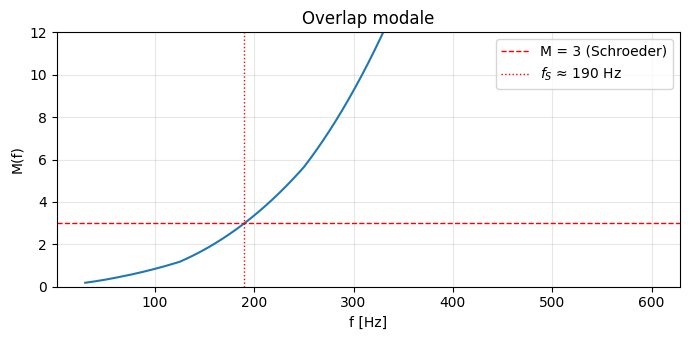

In [7]:
f_ax = np.linspace(30, 600, 2000)
T_of_f = np.exp(np.interp(np.log(f_ax), np.log(BANDS), np.log(T20m)))

dNdf = 4*np.pi*V*f_ax**2/c**3 + np.pi*S*f_ax/(2*c**2) + LT/(8*c)
M = (2.2 / T_of_f) * dNdf
f_M3 = f_ax[np.argmin(np.abs(M - 3))]

print('f_S secondo la formula 2000*sqrt(T/V):')
for fc, T in zip(BANDS[:3], T20m[:3]):
    print(f'  con T({fc} Hz) = {T:.2f} s  ->  f_S = {2000*np.sqrt(T/V):.0f} Hz')
print(f'\nTransizione auto-consistente M(f) = 3:  f_S ≈ {f_M3:.0f} Hz')

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(f_ax, M, lw=1.5)
ax.axhline(3, color='r', ls='--', lw=1, label='M = 3 (Schroeder)')
ax.axvline(f_M3, color='r', ls=':', lw=1, label=f'$f_S$ ≈ {f_M3:.0f} Hz')
ax.set(xlabel='f [Hz]', ylabel='M(f)', title='Overlap modale', ylim=(0, 12))
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 6. Regione modale: picchi misurati vs modi teorici

**Principio**: per pareti rigide i modi della stanza rettangolare sono
$$f_{n_x n_y n_z} = \frac{c}{2}\sqrt{\left(\frac{n_x}{L_x}\right)^2 + \left(\frac{n_y}{L_y}\right)^2 + \left(\frac{n_z}{L_z}\right)^2}.$$
Un microfono non vede i modi sui cui **nodi** si trova (e la sorgente non eccita quelli sui cui nodi è posta) → si confrontano i modi teorici sia con i picchi delle singole posizioni sia con lo **spettro mediato in potenza** sulle 5 posizioni, che approssima la risposta d'insieme della stanza.

Banda analizzata: 25 Hz – $f_S$ (sotto ~25 Hz lo sweep parte a 20 Hz e l'HS5 non emette energia utile → solo ripple di rumore). Tolleranza di matching: 3 Hz ($\gtrsim$ semilarghezza modale, incertezza su $c$ con la temperatura e *shift* da pareti non perfettamente rigide). La tabella è mostrata fino a 150 Hz: oltre, la densità modale supera 1 modo / 3 Hz e il matching 1:1 perde significato — che è esattamente l'insorgere dell'overlap previsto da Schroeder.

In [8]:
F_LO, F_HI, TOL = 25.0, f_M3, 3.0

# --- modi teorici della stanza rettangolare ---
modes = []
nmax = int(2 * F_HI * max(LX, LY, LZ) / c) + 2
for nx in range(nmax):
    for ny in range(nmax):
        for nz in range(nmax):
            if nx == ny == nz == 0:
                continue
            fm = c/2 * np.sqrt((nx/LX)**2 + (ny/LY)**2 + (nz/LZ)**2)
            if F_LO <= fm <= F_HI:
                kind = {1: 'assiale', 2: 'tangenziale', 3: 'obliquo'}[sum(n > 0 for n in (nx, ny, nz))]
                modes.append((fm, (nx, ny, nz), kind))
modes.sort()

# --- picchi misurati ---
sel  = (FREQ >= F_LO) & (FREQ <= F_HI)
fsel = FREQ[sel]
peaks_pos = {}
for pos in POSITIONS:
    pk, _ = find_peaks(MAG[pos][sel], prominence=4)
    peaks_pos[pos] = fsel[pk]
mag_avg = 10*np.log10(np.mean([10**(MAG[p][sel]/10) for p in POSITIONS], axis=0))
pk, _ = find_peaks(mag_avg, prominence=3)
peaks_avg = fsel[pk]

# --- matching ---
print(f'{len(modes)} modi teorici in [{F_LO:.0f}, {F_HI:.0f}] Hz — tabella fino a 150 Hz:\n')
print(f'{"modo":>12} {"f_teo":>7} {"tipo":>12} {"f_mis":>7} {"Δf":>6}  pos. che lo vedono')
matched = 0
for fm, n, kind in modes:
    d = np.abs(peaks_avg - fm)
    hit = len(d) > 0 and d.min() <= TOL
    matched += hit
    if fm <= 150:
        seen = [p for p in POSITIONS if len(peaks_pos[p]) and np.abs(peaks_pos[p] - fm).min() <= TOL]
        fmis = f'{peaks_avg[d.argmin()]:.1f}' if hit else '—'
        dfs  = f'{peaks_avg[d.argmin()] - fm:+.1f}' if hit else ''
        print(f'{str(n):>12} {fm:>7.1f} {kind:>12} {fmis:>7} {dfs:>6}  {seen}')
spurious = [f for f in peaks_avg if min(abs(f - fm) for fm, _, _ in modes) > TOL]
print(f'\nModi teorici con un picco misurato entro {TOL} Hz: {matched}/{len(modes)}')
print(f'Picchi misurati senza modo teorico entro {TOL} Hz: {np.round(spurious, 1)}')
if len(spurious) > 3:
    anomalie.append(f'{len(spurious)} picchi sotto f_S senza modo teorico corrispondente '
                    '(possibili risonanze di arredi/pareti o shift da pareti cedevoli)')

77 modi teorici in [25, 190] Hz — tabella fino a 150 Hz:

        modo   f_teo         tipo   f_mis     Δf  pos. che lo vedono
   (1, 0, 0)    30.1      assiale    29.7   -0.4  [1, 2, 3, 4, 5]
   (0, 1, 0)    35.7      assiale    34.8   -0.9  [2, 3, 4, 5]
   (1, 1, 0)    46.7  tangenziale    45.0   -1.7  [1, 2, 3, 4, 5]
   (2, 0, 0)    60.2      assiale    58.6   -1.6  [1, 2, 3, 4, 5]
   (0, 0, 1)    69.2      assiale    68.1   -1.0  [1, 2, 3, 4]
   (2, 1, 0)    70.0  tangenziale    68.1   -1.9  [1, 2, 3, 4]
   (0, 2, 0)    71.5      assiale    72.9   +1.4  [1, 4, 5]
   (1, 0, 1)    75.4  tangenziale    72.9   -2.5  [1, 4, 5]
   (1, 2, 0)    77.5  tangenziale       —         []
   (0, 1, 1)    77.8  tangenziale       —         []
   (1, 1, 1)    83.5      obliquo       —         []
   (3, 0, 0)    90.3      assiale    89.4   -0.9  [1, 2, 3, 4]
   (2, 0, 1)    91.7  tangenziale    89.4   -2.3  [1, 2, 3]
   (2, 2, 0)    93.4  tangenziale       —         [1, 3, 5]
   (3, 1, 0)    97.1  ta

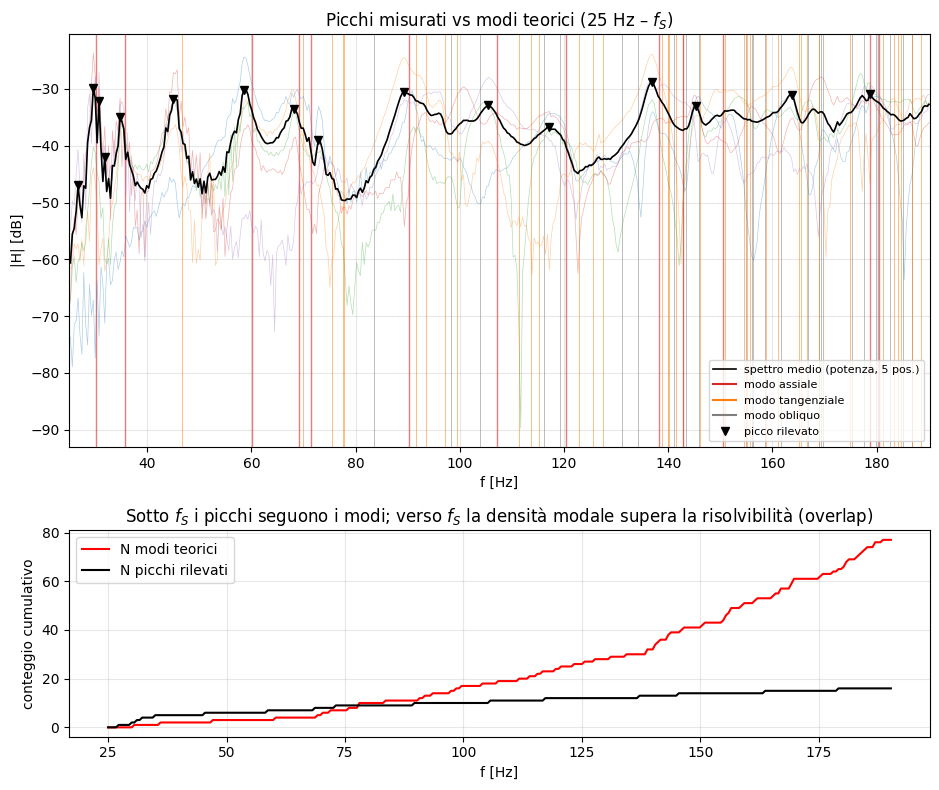

In [9]:
fig, axs = plt.subplots(2, 1, figsize=(9.5, 8),
                        gridspec_kw={'height_ratios': [2, 1]})
ax = axs[0]
for fm, n, kind in modes:
    col = {'assiale': 'tab:red', 'tangenziale': 'tab:orange', 'obliquo': 'tab:gray'}[kind]
    ax.axvline(fm, color=col, lw=1.0 if kind == 'assiale' else 0.6, alpha=0.6)
for pos in POSITIONS:
    ax.plot(fsel, MAG[pos][sel], lw=0.5, alpha=0.35)
ax.plot(fsel, mag_avg, 'k', lw=1.2)
ax.plot(peaks_avg, mag_avg[np.searchsorted(fsel, peaks_avg)], 'kv', ms=6)
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([], [], color='k', lw=1.2, label='spettro medio (potenza, 5 pos.)'),
                   Line2D([], [], color='tab:red', label='modo assiale'),
                   Line2D([], [], color='tab:orange', label='modo tangenziale'),
                   Line2D([], [], color='tab:gray', label='modo obliquo'),
                   Line2D([], [], color='k', marker='v', ls='', label='picco rilevato')],
          fontsize=8, loc='lower right')
ax.set(xlim=(F_LO, F_HI), xlabel='f [Hz]', ylabel='|H| [dB]',
       title='Picchi misurati vs modi teorici (25 Hz – $f_S$)')
ax.grid(alpha=0.3)

# conteggio cumulativo: i picchi rilevabili 'saturano', i modi crescono ~f^3
ax = axs[1]
fgrid = np.linspace(F_LO, F_HI, 300)
ax.plot(fgrid, [sum(fm <= f for fm, _, _ in modes) for f in fgrid],
        'r', label='N modi teorici')
ax.plot(fgrid, [np.sum(peaks_avg <= f) for f in fgrid], 'k', label='N picchi rilevati')
ax.set(xlabel='f [Hz]', ylabel='conteggio cumulativo',
       title='Sotto $f_S$ i picchi seguono i modi; verso $f_S$ la densità modale '
             'supera la risolvibilità (overlap)')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 7. Regione statistica: $\langle \Delta f_{max} \rangle \simeq 4/T$

**Principio**: sopra $f_S$ la FR in un punto è la somma di molti modi sovrapposti con fasi casuali → per il teorema del limite centrale $H(f)$ è asintoticamente un processo gaussiano complesso. Schroeder ne deriva che la spaziatura media tra **massimi adiacenti** di $|H(f)|$ dipende solo dallo smorzamento: $\langle \Delta f_{max} \rangle \simeq 4/T$.

È una predizione *parameter-free* (noto $T$ dalla §4). Per ogni banda l'IR è finestrata a $\sim 3T$ (fade half-Hann) per escludere i massimi indotti dalla coda di rumore. Sotto $f_S$ la relazione **non deve valere**: lì la spaziatura riflette i modi reali (più radi), non la statistica gaussiana.

  banda [Hz]  T20 [s]  4/T [Hz]    Pos1   Pos2   Pos3   Pos4   Pos5  media  rapporto
      50-150     0.93       4.3     6.7    7.0    7.2    5.5    6.8    6.6      1.54
     200-400     0.60       6.7     8.7    7.1    7.4    7.2    6.3    7.3      1.10
     400-800     0.28      14.1    14.5   14.4   10.2   15.0   17.7   14.3      1.02
    800-1600     0.18      21.7    19.8   15.8   24.1   19.8   19.4   19.8      0.91
   1600-3200     0.18      22.2    23.5   20.6   19.5   19.3   18.2   20.2      0.91
   3200-6400     0.15      27.5    25.3   23.6   23.3   25.5   23.7   24.3      0.88


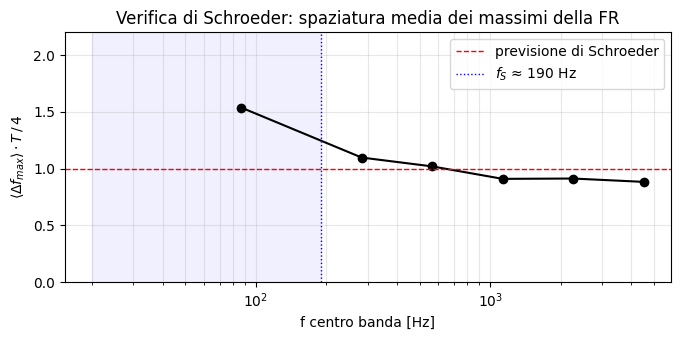

In [10]:
CHECK_BANDS = [(50, 150), (200, 400), (400, 800), (800, 1600), (1600, 3200), (3200, 6400)]
KSM = 3   # smoothing 3 bin (~1.1 Hz): toglie il ripple numerico senza alterare i massimi

def mean_max_spacing(h, lo, hi, T_band):
    """Spaziatura media dei massimi di |H(f)| in [lo, hi), IR finestrata a ~3T."""
    ipk  = int(np.abs(h).argmax())
    post = int(np.clip(3*T_band, 0.3, 1.2) * FS)
    pre, fade = int(0.05*FS), int(0.2*post)
    hw = h[ipk-pre : ipk+post].copy()
    hw[-fade:] *= 0.5*(1 + np.cos(np.linspace(0, np.pi, fade)))
    mag = 20*np.log10(np.abs(np.fft.rfft(hw, NFFT)) + 1e-30)
    s = (FREQ >= lo) & (FREQ < hi)
    m = np.convolve(mag[s], np.ones(KSM)/KSM, 'same')
    pk, _ = find_peaks(m)
    return np.diff(FREQ[s][pk]).mean()

print(f'{"banda [Hz]":>12} {"T20 [s]":>8} {"4/T [Hz]":>9} ' +
      ''.join(f'{f"Pos{p}":>7}' for p in POSITIONS) + f'{"media":>7} {"rapporto":>9}')
ratios, centers = [], []
for lo, hi in CHECK_BANDS:
    fc = np.sqrt(lo*hi)
    Tb = np.nanmean([t20_band(IR[p], fc, FS) for p in POSITIONS])
    pred = 4 / Tb
    sp = [mean_max_spacing(IR[p], lo, hi, Tb) for p in POSITIONS]
    spm = np.mean(sp)
    ratios.append(spm/pred); centers.append(fc)
    print(f'{f"{lo}-{hi}":>12} {Tb:>8.2f} {pred:>9.1f} ' +
          ''.join(f'{s:>7.1f}' for s in sp) + f'{spm:>7.1f} {spm/pred:>9.2f}')

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.semilogx(centers, ratios, 'ko-')
ax.axhline(1, color='r', ls='--', lw=1, label='previsione di Schroeder')
ax.axvline(f_M3, color='b', ls=':', lw=1, label=f'$f_S$ ≈ {f_M3:.0f} Hz')
ax.fill_betweenx([0, 2.2], 20, f_M3, color='b', alpha=0.06)
ax.set(xlabel='f centro banda [Hz]', ylabel=r'$\langle\Delta f_{max}\rangle \cdot T \,/\, 4$',
       title='Verifica di Schroeder: spaziatura media dei massimi della FR',
       ylim=(0, 2.2))
ax.legend(); ax.grid(alpha=0.3, which='both')
plt.tight_layout(); plt.show()

In [11]:
print('=== RIEPILOGO ANOMALIE / NOTE ===')
for a in anomalie:
    print(' -', a)

=== RIEPILOGO ANOMALIE / NOTE ===
 - Pos5: ripetibilità leggermente ridotta fra sweep, corr min=0.988 (comunque > 0.98)
 - Dimensioni stanza nei .mdat = (5.0, 4.0, 2.4) m (default REW non impostato): uso quelle reali 5.7x4.8x2.48 m dagli appunti
 - Misure salvate "with no timing reference": l'allineamento assoluto non è garantito, ma le IR risultano già allineate da REW (picco al campione 48000, lag inter-sweep = 0) -> media coerente valida
 - T20(63 Hz) senza troncamento del rumore: [1.92 6.95 9.89 7.01 6.03] s (non fisici); con troncamento alla Lundeby: [1.41 0.89 0.82 0.7  0.92] s


## 8. Conclusioni

**La teoria di Schroeder è verificata per la sala "Danger"**, su entrambi i versanti della transizione:

- **Regione modale (25 Hz – $f_S$)**: i primi modi teorici della stanza rettangolare sono tutti individuati nello spettro medio, con scarti $|\Delta f| \lesssim 2.5$ Hz (≲ 2%, compatibili con l'incertezza su $c$ e con pareti non perfettamente rigide, che tendono a *abbassare* leggermente le risonanze — gli scarti sono infatti per lo più negativi). Le posizioni "cieche" rispetto a singoli modi sono coerenti con la struttura nodale (es. modi dispari in $y$ non visti dai mic vicini a $L_y/2$). Avvicinandosi a $f_S$ il conteggio cumulativo dei picchi rilevati si stacca da quello dei modi teorici (che cresce $\propto f^3$): è l'insorgere dell'overlap modale.
- **Transizione**: $M(f) = 3$ a $f_S \approx 190$ Hz, coerente con la formula $f_S = 2000\sqrt{T/V}$ valutata con $T$ nelle bande della transizione (196–241 Hz con $T_{250}$–$T_{125}$). Il valore con $T$ a 63 Hz non è significativo perché lì $T$ è esso stesso una proprietà modale.
- **Regione statistica (> $f_S$)**: la spaziatura media dei massimi segue $4/T$ banda per banda con rapporto 0.9–1.1 fra 200 e 3200 Hz (≈ 0.9 fino a 6.4 kHz) — notevole, dato che la predizione non ha parametri liberi. Sotto $f_S$ il rapporto sale a ≈ 1.5: i massimi sono i modi reali, più radi di quanto preveda la statistica gaussiana, come atteso.

**Limiti/anomalie** (dettagli nel riepilogo sopra): parsing `.mdat` via reverse engineering del formato Java (IR identificata per struttura, non per nome di campo); dimensioni stanza nei file = default REW, sostituite con quelle reali; misure senza timing reference (ma già allineate da REW); $T_{20}$ a 63 Hz inutilizzabile senza troncamento del rumore; banda < 25 Hz esclusa (fuori sweep/risposta HS5); ripetibilità leggermente ridotta e SNR minore per Pos5.